In [1]:
!pip install git+https://github.com/ai-forever/gigacheck --no-deps

  Cloning https://github.com/ai-forever/gigacheck to /tmp/pip-req-build-_uu6t7yh
  Running command git clone --filter=blob:none --quiet https://github.com/ai-forever/gigacheck /tmp/pip-req-build-_uu6t7yh
  Resolved https://github.com/ai-forever/gigacheck to commit 8cdbe6a1ce628b49b4aa0794edf7a425a47a774c
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for gigacheck: filename=gigacheck-0.0.1.dev0-py3-none-any.whl size=75537 sha256=19ce9150fec8c692a381c76fffef3a4a53f399382d0b11a71321362fe1b19345
  Stored in directory: /tmp/pip-ephem-wheel-cache-zy1i3r4f/wheels/87/3d/f6/bc41029810b94a6965648211866f3858218be188b1e0f7eebc
Successfully built gigacheck


In [2]:
!pip install dacite omegaconf loguru

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gigacheck 0.0.1.dev0 requires bitsandbytes, which is not installed.
gigacheck 0.0.1.dev0 requires clearml, which is not installed.
gigacheck 0.0.1.dev0 requires deepspeed==0.12.6, which is not installed.
gigacheck 0.0.1.dev0 requires evaluate, which is not installed.
gigacheck 0.0.1.dev0 requires intervaltree, which is not installed.
gigacheck 0.0.1.dev0 requires accelerate==1.2.1, but you have accelerate 1.15.0 which is incompatible.
gigacheck 0.0.1.dev0 requires boto3==1.20.39, but you have boto3 1.41.5 which is incompatible.
gigacheck 0.0.1.dev0 requires numpy==1.26.4, but you have numpy 2.1.3 which is incompatible.
gigacheck 0.0.1.dev0 requires omegaconf==2.1.1, but you have omegaconf 2.4.0 which is incompatible.
gigacheck 0.0.1.dev0 requires peft==0.14.0, but you have peft 0.21.2 which is incompatible.
gigach

In [3]:
!pip install langdetect

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 19.8 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for langdetect: filename=langdetect-1.0.9-py3-none-any.whl size=993332 sha256=61040b65655c17e5247a606e23b7074498b077f6a39e76aca3b8b6312641e5ae
  Stored in directory: /root/.cache/pip/wheels/eb/87/25/2dddf1c94e1786054e25022ec5530bfed52bad86d882999c48
Successfully built langdetect


In [4]:
import os

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import torch
from transformers import AutoModel
from datasets import load_dataset, Dataset
import pandas as pd
from tqdm import tqdm
from sklearn.metrics import accuracy_score, classification_report
import gc
from collections import defaultdict
from langdetect import detect, DetectorFactory

# Для воспроизводимости определения языка
DetectorFactory.seed = 0

# --- 1. Загрузка модели ---
MODEL_NAME = "iitolstykh/GigaCheck-Classifier-Multi"
print(f"Загрузка модели {MODEL_NAME}...")

classifier = AutoModel.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True,
    device_map="auto",
    torch_dtype=torch.bfloat16,
    low_cpu_mem_usage=True
)
classifier.eval()

# --- 2. Загрузка датасета SemEval-2024 (Multilingual) ---
print("Загрузка SemEval-2024 Task 8 (Subtask A Multilingual)...")
# Используем неофициальное, но полное зеркало на Hugging Face
dataset = load_dataset("d0rj/SemEval2024-task8", "subtaskA_multilingual", split="test")

print(f"Колонки датасета: {dataset.column_names}")
print(f"Всего примеров в тестовом сплите: {len(dataset)}")

# --- 3. Формирование равномерной выборки по языкам ---
# Автоматически определяем доступные языки
target_languages = set()
# Сначала пробуем взять из колонки 'lang', если она есть
if 'lang' in dataset.column_names:
    for example in tqdm(dataset, desc="Сбор языков из колонки 'lang'"):
        lang = example.get('lang')
        if lang and isinstance(lang, str):
            target_languages.add(lang.lower().strip())
else:
    # Если колонки нет, определяем язык на лету (берем первые 5000 примеров для скорости)
    print("Колонка 'lang' не найдена. Определяем языки автоматически...")
    for i, example in enumerate(tqdm(dataset, desc="Автоопределение языков")):
        if i >= 5000: # Ограничиваем выборку для скорости
            break
        text = example.get('text', '')
        if text and isinstance(text, str) and len(text.strip()) > 20:
            try:
                lang = detect(text[:500])
                target_languages.add(lang)
            except:
                pass

target_languages = sorted(list(target_languages))
print(f"Обнаруженные языки: {target_languages}")

# Оставляем только те языки, которые нас интересуют (например, en, ar, de, it)
desired_langs = ['en', 'ar', 'de', 'it']
final_langs = [l for l in target_languages if l in desired_langs]
if not final_langs:
    final_langs = target_languages[:4] # Если нужных нет, берем любые 4

print(f"Будем тестировать на языках: {final_langs}")

samples_per_class_per_lang = 10
lang_label_to_texts = defaultdict(lambda: {"human": [], "ai": []})

print("Сбор текстов по языкам и классам...")
for example in tqdm(dataset, desc="Сканирование"):
    text = example.get('text', '')
    label = example.get('label') # 0 = human, 1 = ai
    
    if not text or not isinstance(text, str) or len(text.strip()) == 0:
        continue

    # Определяем язык
    lang = example.get('lang')
    if lang and isinstance(lang, str):
        lang = lang.lower().strip()
    else:
        try:
            lang = detect(text[:500])
        except:
            continue

    if lang not in final_langs:
        continue

    if label == 0:
        lang_label_to_texts[lang]["human"].append(text)
    elif label == 1:
        lang_label_to_texts[lang]["ai"].append(text)
    
    # Оптимизация: если для всех языков уже набрали достаточно, можно остановиться
    # (но для простоты просто собираем все, так как датасет не гигантский)

# Формируем сбалансированный список
balanced_data = []
for lang in final_langs:
    human_texts = lang_label_to_texts[lang]["human"]
    ai_texts = lang_label_to_texts[lang]["ai"]
    
    n = min(samples_per_class_per_lang, len(human_texts), len(ai_texts))
    if n == 0:
        print(f"  Язык {lang}: недостаточно данных (human={len(human_texts)}, ai={len(ai_texts)})")
        continue
    
    for text in human_texts[:n]:
        balanced_data.append({"text": text, "true_label": "human", "language": lang})
    for text in ai_texts[:n]:
        balanced_data.append({"text": text, "true_label": "ai", "language": lang})
    
    print(f"  Язык {lang}: взято {n} human, {n} ai")

df_eval = pd.DataFrame(balanced_data)
print(f"\nИтоговая выборка: {len(df_eval)} текстов")
print(df_eval['true_label'].value_counts())

if len(df_eval) == 0:
    raise SystemExit("Не удалось собрать тексты. Проверьте данные.")

# --- 4. Инференс ---
results = []
batch_size = 1

for i in tqdm(range(0, len(df_eval), batch_size), desc="Инференс"):
    batch = df_eval.iloc[i : i + batch_size]
    texts_batch = [str(t).replace("\n", " ")[:2000] for t in batch["text"]] # Обрезаем до 2000 символов для скорости

    with torch.no_grad():
        outputs = classifier(texts_batch)

    probs = None
    if hasattr(outputs, 'logits'):
        probs = torch.nn.functional.softmax(outputs.logits, dim=-1)
    elif isinstance(outputs, tuple) and len(outputs) > 0 and isinstance(outputs[0], torch.Tensor):
        probs = torch.nn.functional.softmax(outputs[0], dim=-1)

    max_probs = probs.max(dim=-1).values.cpu().tolist() if probs is not None else [1.0] * len(texts_batch)

    pred_ids = outputs.pred_label_ids.cpu().tolist()
    pred_labels = [classifier.config.id2label[int(pid)] for pid in pred_ids]

    true_labels = batch["true_label"]
    languages = batch["language"]

    for text, true, pred, lang, prob in zip(
        texts_batch, true_labels, pred_labels, languages, max_probs
    ):
        results.append({
            "text": text,
            "true_label": true,
            "predicted_label": pred,
            "language": lang,
            "predicted_prob": prob
        })

# --- 5. Сохранение и метрики ---
df_results = pd.DataFrame(results)
os.makedirs("results", exist_ok=True)
output_path = "results/semeval_multilingual_predictions.csv"
df_results.to_csv(output_path, index=False, encoding="utf-8")

print("\n" + "="*50)
print("РЕЗУЛЬТАТЫ ТЕСТИРОВАНИЯ (SemEval-2024 Multilingual)")
print("="*50)
print(f"Всего обработано текстов: {len(df_results)}")
print(f"Данные сохранены в: {output_path}")

y_true = df_results["true_label"].str.lower().str.strip()
y_pred = df_results["predicted_label"].str.lower().str.strip()

print("\n--- ОБЩИЕ МЕТРИКИ ---")
acc = accuracy_score(y_true, y_pred)
print(f"Accuracy (Точность): {acc:.4f}")
print("\nДетальный отчет по классам:")
print(classification_report(y_true, y_pred, zero_division=0))

print("\n--- МЕТРИКИ ПО ЯЗЫКАМ ---")
for lang in df_results['language'].unique():
    subset = df_results[df_results['language'] == lang]
    if len(subset) > 0:
        acc_lang = accuracy_score(subset['true_label'], subset['predicted_label'])
        print(f"{lang.upper()}: Accuracy = {acc_lang:.4f} (N={len(subset)})")

gc.collect()
torch.cuda.empty_cache()

Загрузка модели iitolstykh/GigaCheck-Classifier-Multi...


config.json:   0%|          | 0.00/1.10k [00:00<?, ?B/s]

configuration_gigacheck.py:   0%|          | 0.00/767 [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/iitolstykh/GigaCheck-Classifier-Multi:
- configuration_gigacheck.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


modeling_gigacheck.py:   0%|          | 0.00/6.11k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/iitolstykh/GigaCheck-Classifier-Multi:
- modeling_gigacheck.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


... (23 outputs left out)

Сканирование: 100%|██████████| 42378/42378 [01:56<00:00, 364.87it/s]


  Язык ar: взято 10 human, 10 ai
  Язык de: взято 10 human, 10 ai
  Язык en: взято 10 human, 10 ai
  Язык it: взято 10 human, 10 ai

Итоговая выборка: 80 текстов
true_label
human    40
ai       40
Name: count, dtype: int64


Инференс: 100%|██████████| 80/80 [04:52<00:00,  3.65s/it]



РЕЗУЛЬТАТЫ ТЕСТИРОВАНИЯ (SemEval-2024 Multilingual)
Всего обработано текстов: 80
Данные сохранены в: results/semeval_multilingual_predictions.csv

--- ОБЩИЕ МЕТРИКИ ---
Accuracy (Точность): 0.9250

Детальный отчет по классам:
              precision    recall  f1-score   support

          ai       0.97      0.88      0.92        40
       human       0.89      0.97      0.93        40

    accuracy                           0.93        80
   macro avg       0.93      0.93      0.92        80
weighted avg       0.93      0.93      0.92        80


--- МЕТРИКИ ПО ЯЗЫКАМ ---
AR: Accuracy = 0.9500 (N=20)
DE: Accuracy = 0.8500 (N=20)
EN: Accuracy = 0.9000 (N=20)
IT: Accuracy = 1.0000 (N=20)


In [5]:
import pandas as pd
import textwrap
from collections import Counter

# --- 1. Загрузка сохранённых результатов ---
CSV_PATH = "results/semeval_multilingual_predictions.csv"
df = pd.read_csv(CSV_PATH)

print("="*80)
print("ОБЩАЯ ИНФОРМАЦИЯ О ВЫБОРКЕ")
print("="*80)
print(f"Всего текстов: {len(df)}")
print(f"Колонки: {df.columns.tolist()}")

# --- 2. Распределение по языкам и классам ---
print("\n" + "="*80)
print("РАСПРЕДЕЛЕНИЕ ПО ЯЗЫКАМ И КЛАССАМ")
print("="*80)
pivot = df.pivot_table(index='language', columns='true_label', aggfunc='size', fill_value=0)
print(pivot)

# --- 3. Длины текстов ---
df['length'] = df['text'].str.len()
print("\n" + "="*80)
print("ДЛИНЫ ТЕКСТОВ (в символах)")
print("="*80)
print(df.groupby(['language', 'true_label'])['length'].agg(['mean', 'min', 'max']).round(0))

# --- 4. Примеры текстов (по 1 на каждый язык и класс) ---
print("\n" + "="*80)
print("ПРИМЕРЫ ТЕКСТОВ")
print("="*80)

for lang in sorted(df['language'].unique()):
    for label in ['human', 'ai']:
        subset = df[(df['language'] == lang) & (df['true_label'] == label)]
        if len(subset) == 0:
            continue
        text = str(subset.iloc[0]['text']).replace("\n", " ")
        pred = subset.iloc[0]['predicted_label']
        print(f"\n[{lang.upper()} / {label.upper()}] (длина {len(text)}, предсказано: {pred})")
        print(textwrap.fill(text[:400] + "...", width=80))
        print("-" * 80)

# --- 5. Детекция "неправильного" скрипта (на случай, если языки перепутаны) ---
import re
def detect_script(text):
    cyrillic = len(re.findall(r'[а-яА-ЯёЁ]', text))
    arabic = len(re.findall(r'[\u0600-\u06FF]', text))
    latin = len(re.findall(r'[a-zA-Z]', text))
    if cyrillic > max(arabic, latin): return "Cyrillic"
    if arabic > max(cyrillic, latin): return "Arabic"
    if latin > max(cyrillic, arabic): return "Latin"
    return "Other"

print("\n" + "="*80)
print("ПРОВЕРКА СООТВЕТСТВИЯ ЯЗЫКА И ПИСЬМЕННОСТИ")
print("="*80)
df['script'] = df['text'].apply(lambda x: detect_script(str(x)))
for lang in sorted(df['language'].unique()):
    subset = df[df['language'] == lang]
    scripts = Counter(subset['script'])
    print(f"{lang.upper()}: {dict(scripts)}")

ОБЩАЯ ИНФОРМАЦИЯ О ВЫБОРКЕ
Всего текстов: 80
Колонки: ['text', 'true_label', 'predicted_label', 'language', 'predicted_prob']

РАСПРЕДЕЛЕНИЕ ПО ЯЗЫКАМ И КЛАССАМ
true_label  ai  human
language             
ar          10     10
de          10     10
en          10     10
it          10     10

ДЛИНЫ ТЕКСТОВ (в символах)
                       mean   min   max
language true_label                    
ar       ai          1485.0   453  2000
         human       1819.0  1021  2000
de       ai          2000.0  1995  2000
         human       1988.0  1875  2000
en       ai          1794.0  1083  2000
         human       1715.0  1080  2000
it       ai          1175.0  1010  1339
         human       1220.0  1158  1314

ПРИМЕРЫ ТЕКСТОВ

[AR / HUMAN] (длина 2000, предсказано: human)
بدأت الشرطة الهندية استخدام تقنية التعرف على الوجه لفحص الحشود الضخمة التي
تتظاهر ضد قانون الجنسية الجديد القائم على أساس الدين، فيما دافعت السلطات عن
إجراءاتها القمعية ضد المسلمين المحتجين وهددت بمصادرة ممتلكاتهم. 

ОБЩИЕ МЕТРИКИ (BLUFF - 10 ЯЗЫКОВ)
Accuracy: 0.9250

Classification Report (Precision/Recall/F1):
              precision    recall  f1-score   support

          ai       0.97      0.88      0.92        40
       human       0.89      0.97      0.93        40

    accuracy                           0.93        80
   macro avg       0.93      0.93      0.92        80
weighted avg       0.93      0.93      0.92        80



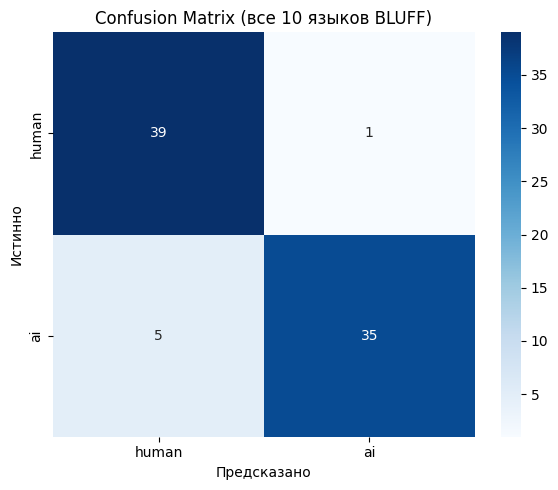


Построение графиков по языкам...


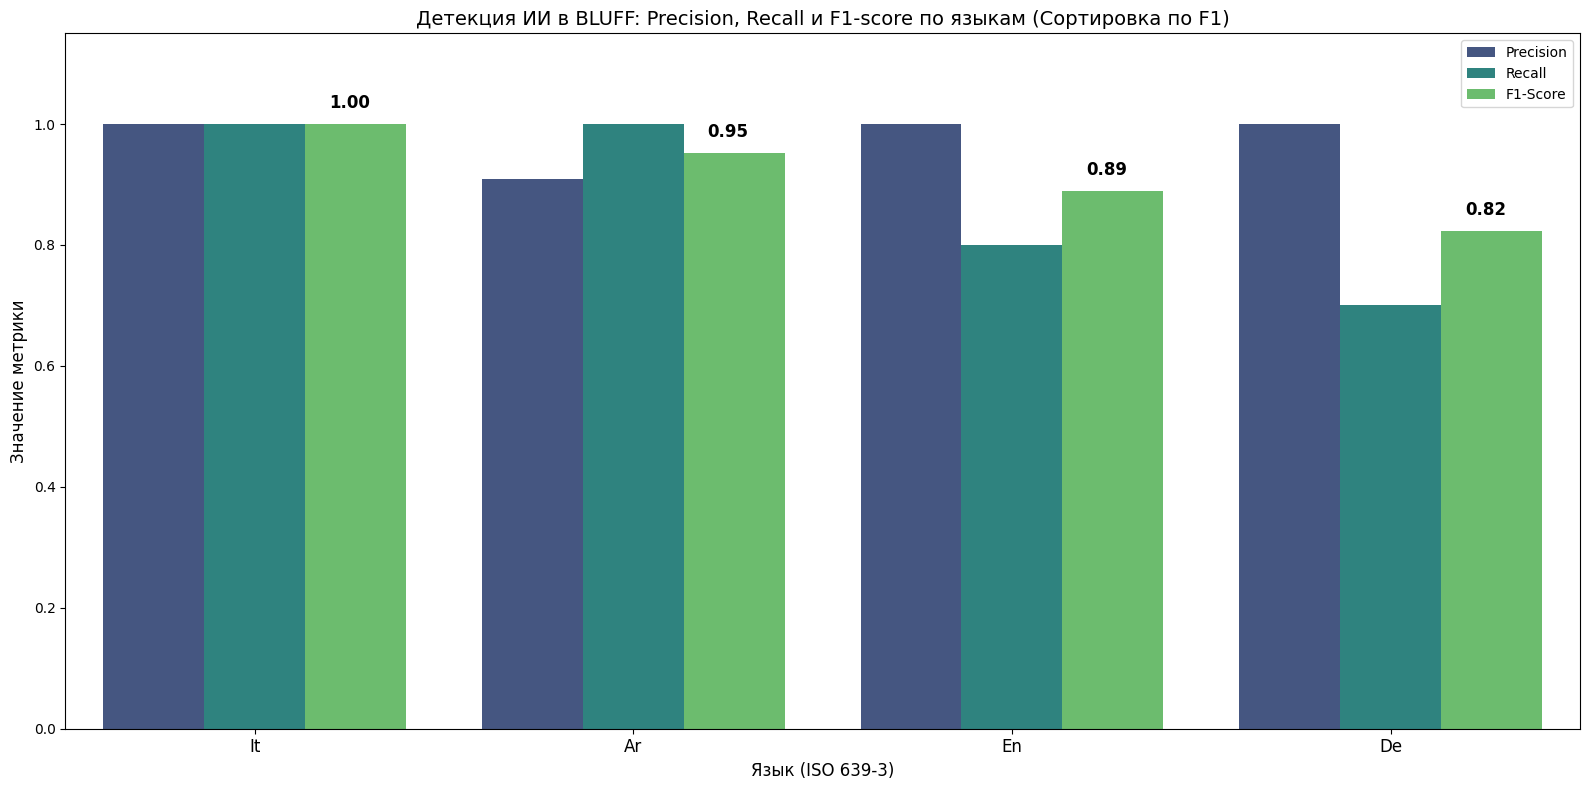

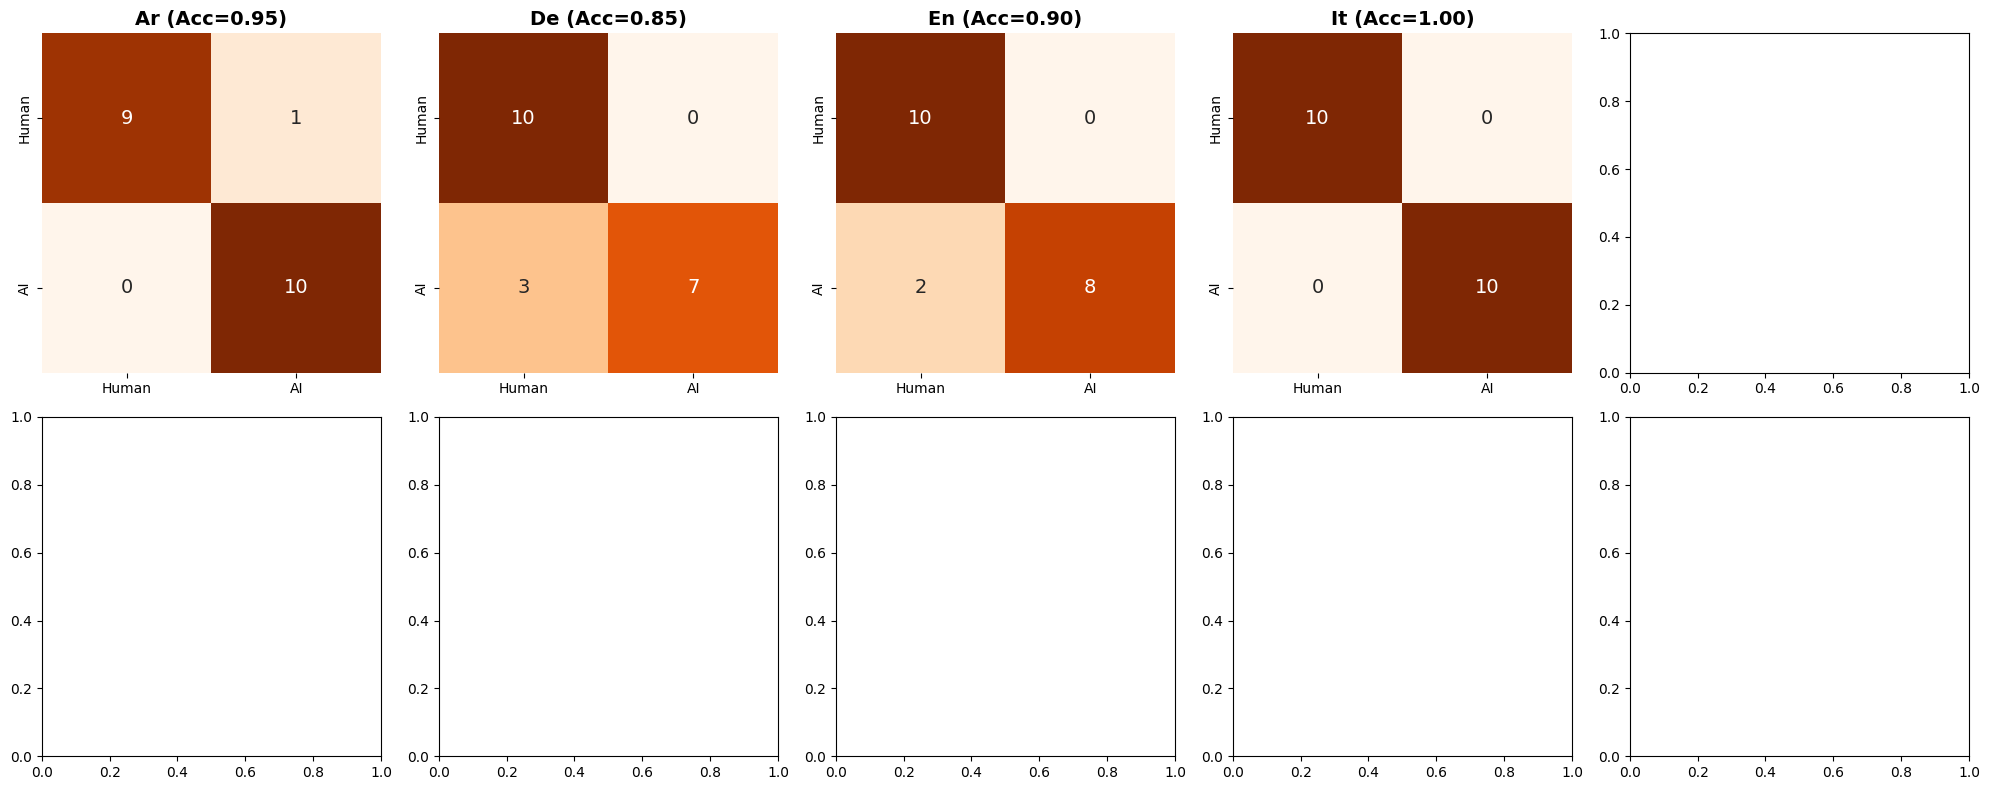


Все графики сохранены в папку 'plots'.


In [6]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_recall_fscore_support
import os

# --- 1. Загрузка результатов ---
CSV_PATH = "/kaggle/working/results/semeval_multilingual_predictions.csv"
df = pd.read_csv(CSV_PATH)

# Приводим метки к единому виду
df["true_label"] = df["true_label"].str.lower().str.strip()
df["predicted_label"] = df["predicted_label"].str.lower().str.strip()
# Делаем названия языков заглавными (eng -> Eng)
df["language_name"] = df["language"].str.capitalize()

os.makedirs("plots", exist_ok=True)

# --- 2. Общие метрики (Текстовый вывод) ---
print("=" * 50)
print("ОБЩИЕ МЕТРИКИ (BLUFF - 10 ЯЗЫКОВ)")
print("=" * 50)
print(f"Accuracy: {accuracy_score(df['true_label'], df['predicted_label']):.4f}")
print("\nClassification Report (Precision/Recall/F1):")
print(classification_report(df["true_label"], df["predicted_label"], zero_division=0))

# --- 3. Общая Confusion Matrix ---
plt.figure(figsize=(6, 5))
cm = confusion_matrix(df["true_label"], df["predicted_label"], labels=["human", "ai"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["human", "ai"], yticklabels=["human", "ai"])
plt.title("Confusion Matrix (все 10 языков BLUFF)")
plt.xlabel("Предсказано")
plt.ylabel("Истинно")
plt.tight_layout()
plt.savefig("plots/bluff_confusion_matrix_all.png", dpi=150)
plt.show()

# --- 4. Вспомогательная функция для расчета P/R/F1 по категориям ---
def get_metrics_by_category(df, category_col, target_class='ai'):
    results = []
    for cat in df[category_col].unique():
        subset = df[df[category_col] == cat]
        if len(subset) == 0: continue
        
        p, r, f1, _ = precision_recall_fscore_support(
            subset['true_label'], subset['predicted_label'], 
            labels=[target_class], average=None, zero_division=0
        )
        
        results.append({
            category_col: cat,
            'Precision': p[0],
            'Recall': r[0],
            'F1-Score': f1[0],
            'Accuracy': accuracy_score(subset['true_label'], subset['predicted_label'])
        })
    return pd.DataFrame(results)

# --- 5. Графики P/R/F1 по 10 ЯЗЫКАМ ---
print("\nПостроение графиков по языкам...")
lang_metrics = get_metrics_by_category(df, 'language_name')
# Сортируем по F1-score (от лучшего к худшему)
lang_metrics = lang_metrics.sort_values('F1-Score', ascending=False).reset_index(drop=True)

lang_melted = lang_metrics.melt(id_vars=['language_name'], 
                                value_vars=['Precision', 'Recall', 'F1-Score'], 
                                var_name='Metric', value_name='Score')

# Делаем график комфортной ширины для 10 языков
plt.figure(figsize=(16, 8)) 
sns.barplot(data=lang_melted, x='language_name', y='Score', hue='Metric', palette='viridis')
plt.title("Детекция ИИ в BLUFF: Precision, Recall и F1-score по языкам (Сортировка по F1)", fontsize=14)
plt.ylim(0, 1.15)
plt.xlabel("Язык (ISO 639-3)", fontsize=12)
plt.ylabel("Значение метрики", fontsize=12)
plt.legend(loc='upper right')
plt.xticks(fontsize=12)

# Подписываем значения для F1
for i, row in lang_metrics.iterrows():
    f1_val = row['F1-Score']
    plt.text(i + 0.25, f1_val + 0.02, f"{f1_val:.2f}", ha='center', va='bottom', 
             fontweight='bold', color='black', fontsize=12)

plt.tight_layout()
plt.savefig("plots/bluff_prf1_by_language.png", dpi=150)
plt.show()

# --- 6. Матрицы ошибок по 10 языкам (Сетка 2x5) ---
languages = sorted(df["language_name"].unique())
num_langs = len(languages)

# Для 10 языков идеально подходит сетка 2 ряда по 5 колонок
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, lang in enumerate(languages):
    subset = df[df["language_name"] == lang]
    cm_lang = confusion_matrix(subset["true_label"], subset["predicted_label"], labels=["human", "ai"])
    
    sns.heatmap(cm_lang, annot=True, fmt="d", cmap="Oranges", ax=axes[i],
                xticklabels=["Human", "AI"], yticklabels=["Human", "AI"], cbar=False,
                annot_kws={"size": 14})
    
    acc = accuracy_score(subset["true_label"], subset["predicted_label"])
    axes[i].set_title(f"{lang} (Acc={acc:.2f})", fontsize=14, fontweight='bold')
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")

plt.tight_layout()
plt.savefig("plots/bluff_confusion_matrix_by_language.png", dpi=150)
plt.show()

print("\nВсе графики сохранены в папку 'plots'.")